In [3]:
import h5py
import os
import numpy as np
from sklearn.utils import resample

In [2]:
new_root = 'D:/LCZ42/'
img_fname = 'training.h5'
start_idx = 0
end_idx = 20000

In [3]:
h5_file = os.path.join(new_root,img_fname)

with h5py.File(h5_file, 'r') as fid1:
    sen1_shape = fid1['sen1'].shape
    print("sen1_data shape:", sen1_shape)

with h5py.File(h5_file, 'r') as fid1:
    sen1_data = np.array(fid1['sen1'][start_idx:end_idx])  # (N, patchSize, patchSize, 8)
    sen2_data = np.array(fid1['sen2'][start_idx:end_idx])  # (N, patchSize, patchSize, 10)
    print("Taille de sen1_data revu : ", sen1_data.shape)
    print("Taille de sen2_data revu : ", sen2_data.shape)
    label_data = np.array(fid1['label'][start_idx:end_idx])
    print("Donnée label en one-hot coding : \n", label_data)


sen1_data shape: (352366, 32, 32, 8)
Taille de sen1_data revu :  (20000, 32, 32, 8)
Taille de sen2_data revu :  (20000, 32, 32, 10)
Donnée label en one-hot coding : 
 [[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 ...
 [0. 1. 0. ... 0. 0. 0.]
 [0. 0. 1. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]]


In [4]:
# Comme initialement les label_data sont en one-hot encoding
labels = np.argmax(label_data, axis=1)
classes = np.unique(labels)

n_par_classe = 500  # largement suffisant pour l'EDA

indices = []
for c in classes:
    idx_c = np.where(labels == c)[0]
    idx_sample = resample(idx_c, n_samples=min(n_par_classe, len(idx_c)), replace=False, random_state=42)
    print(f"Taille de la classe LCZ {c+1} : ", idx_sample.shape)
    indices.append(idx_sample)

indices = np.concatenate(indices)
sen1_sample = sen1_data[indices]
sen2_sample  = sen2_data[indices]
label_sample = label_data[indices]

Taille de la classe LCZ 1 :  (281,)
Taille de la classe LCZ 2 :  (500,)
Taille de la classe LCZ 3 :  (500,)
Taille de la classe LCZ 4 :  (500,)
Taille de la classe LCZ 5 :  (500,)
Taille de la classe LCZ 6 :  (500,)
Taille de la classe LCZ 7 :  (192,)
Taille de la classe LCZ 8 :  (500,)
Taille de la classe LCZ 9 :  (500,)
Taille de la classe LCZ 10 :  (500,)
Taille de la classe LCZ 11 :  (500,)
Taille de la classe LCZ 12 :  (482,)
Taille de la classe LCZ 13 :  (500,)
Taille de la classe LCZ 14 :  (500,)
Taille de la classe LCZ 15 :  (144,)
Taille de la classe LCZ 16 :  (467,)
Taille de la classe LCZ 17 :  (500,)


## Etude variance des canaux par intra et inter-classe pour comparer les inter et intra-classes et estimer ce qui sera plus ou moins déterminants

In [5]:
# Pour Sentinel-2
fisher_ratios_s2 = []
for b in range(sen2_data.shape[-1]):
    canal = sen2_data[:, :, :, b].reshape(sen2_data.shape[0], -1)  # (N, patchSize²)
    moyenne_par_patch = canal.mean(axis=1)          # (N,) — un scalaire par patch

    # Variance intra-classe : moyenne des variances par classe
    variance_intra = 0
    for c in classes:
        vals = moyenne_par_patch[labels == c]
        variance_intra += vals.var()
    variance_intra /= len(classes)
    print(f"Variance intra-classe pour la bande {b+1}: ", round(variance_intra,5))

    # Variance inter-classe : variance des moyennes par classe
    moyennes_classes = [moyenne_par_patch[np.argmax(label_data, axis=1) == c].mean() for c in classes]
    variance_inter = np.var(moyennes_classes)
    print(f"Variance inter-classes pour la bande {b+1} : ", round(variance_inter, 5))


    # Ratio de Fisher : plus il est élevé, plus le canal est discriminant
    ratio = variance_inter / variance_intra
    print("Ce qui donne le ratio suivant : ", round(ratio,4))
    fisher_ratios_s2.append(ratio)

Variance intra-classe pour la bande 1:  0.00053
Variance inter-classes pour la bande 1 :  0.0007
Ce qui donne le ratio suivant :  1.313
Variance intra-classe pour la bande 2:  0.00091
Variance inter-classes pour la bande 2 :  0.00115
Ce qui donne le ratio suivant :  1.2627
Variance intra-classe pour la bande 3:  0.00184
Variance inter-classes pour la bande 3 :  0.00252
Ce qui donne le ratio suivant :  1.366
Variance intra-classe pour la bande 4:  0.0018
Variance inter-classes pour la bande 4 :  0.00229
Ce qui donne le ratio suivant :  1.2751
Variance intra-classe pour la bande 5:  0.00209
Variance inter-classes pour la bande 5 :  0.00241
Ce qui donne le ratio suivant :  1.1545
Variance intra-classe pour la bande 6:  0.00266
Variance inter-classes pour la bande 6 :  0.00311
Ce qui donne le ratio suivant :  1.1684
Variance intra-classe pour la bande 7:  0.00245
Variance inter-classes pour la bande 7 :  0.00302
Ce qui donne le ratio suivant :  1.2338
Variance intra-classe pour la bande 8:

On observe que les ratios sont à peu près équivalents, pas tant de différence, ce sera sûrement l'information spatiale qui sera discriminant pour les LCZs

In [6]:
# Pour Sentinel-1
fisher_ratios_s1 = []
for b in range(sen1_data.shape[-1]):
    canal = sen1_data[:, :, :, b].reshape(sen1_data.shape[0], -1)  # (N, patchSize²)
    moyenne_par_patch = canal.mean(axis=1)          # (N,) — un scalaire par patch

    # Variance intra-classe : moyenne des variances par classe
    variance_intra = 0
    for c in classes:
        vals = moyenne_par_patch[labels == c]
        variance_intra += vals.var()
    variance_intra /= len(classes)
    print(f"Variance intra-classe pour la bande {b+1}: ", round(variance_intra, 6))

    # Variance inter-classe : variance des moyennes par classe
    moyennes_classes = [moyenne_par_patch[np.argmax(label_data, axis=1) == c].mean() for c in classes]
    variance_inter = np.var(moyennes_classes)
    print(f"Variance inter-classes pour la bande {b+1} : ", round(variance_inter, 6))


    # Ratio de Fisher : plus il est élevé, plus le canal est discriminant
    ratio = variance_inter / variance_intra
    print("Ce qui donne le ratio suivant : ", round(ratio,4))
    fisher_ratios_s1.append(ratio)


Variance intra-classe pour la bande 1:  8e-05
Variance inter-classes pour la bande 1 :  0.0
Ce qui donne le ratio suivant :  0.0054
Variance intra-classe pour la bande 2:  7.8e-05
Variance inter-classes pour la bande 2 :  1e-06
Ce qui donne le ratio suivant :  0.0066
Variance intra-classe pour la bande 3:  0.000488
Variance inter-classes pour la bande 3 :  1e-06
Ce qui donne le ratio suivant :  0.0014
Variance intra-classe pour la bande 4:  0.000436
Variance inter-classes pour la bande 4 :  1e-06
Ce qui donne le ratio suivant :  0.0027
Variance intra-classe pour la bande 5:  0.028232
Variance inter-classes pour la bande 5 :  0.005118
Ce qui donne le ratio suivant :  0.1813
Variance intra-classe pour la bande 6:  1.467415
Variance inter-classes pour la bande 6 :  0.139691
Ce qui donne le ratio suivant :  0.0952
Variance intra-classe pour la bande 7:  0.013509
Variance inter-classes pour la bande 7 :  2.1e-05
Ce qui donne le ratio suivant :  0.0016
Variance intra-classe pour la bande 8: 

Ici, on voit que les bandes 5 et 6 sont pas mal et montrent que les bandes 5 et 6 sont bien plus discriminantes, bien que la varaince intra-classe de la bande 6 est bien trop grande également ce qui montre qu'il y a beaucoup de bruit. Donc bande 5 bonne idée.

Donc Sentinel-1 seul serait totalement insuffisant pour discriminer les LCZ

Donc prendre les bandes 5 et 6 seulement pour la suite

## Puis ensuite passage par les boxplots et surtout violin plots (analyse de densité) pour visualiser mes variations de chaque canal par LCZ 

In [7]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [8]:
LCZ_NAMES = {
    0: "LCZ 1", 1: "LCZ 2", 2: "LCZ 3", 3: "LCZ 4",
    4: "LCZ 5", 5: "LCZ 6", 6: "LCZ 7", 7: "LCZ 8",
    8: "LCZ 9", 9: "LCZ 10", 10: "LCZ 11", 11: "LCZ 12",
    12: "LCZ 13", 13: "LCZ 14", 14: "LCZ 15", 15: "LCZ 16", 16: "LCZ 17"
}

In [9]:
def plot_violin_par_bande(sat_type:str, label_sample, n_bandes):
    """
    data          : (N, patchSize, patchSize, n_bandes)
    label_sample  : (N,) entiers — classes déjà décodées via argmax
    """
    classes = np.unique(label_sample)
    n_classes = len(classes)
    
    if sat_type=="Sen-1":
        data = sen1_sample
        fisher_ratios = fisher_ratios_s1
    elif sat_type=="Sen-2":
        data = sen2_sample
        fisher_ratios = fisher_ratios_s2
    else : 
        raise ValueError(f"sat_type doit être 'Sen-1' ou 'Sen-2' reçu : '{sat_type}'")
    
    for b in range(n_bandes):
        canal = data[:, :, :, b].reshape(data.shape[0], -1)
        moyenne_par_patch = canal.mean(axis=1)  # (N,)
        
        # Données groupées par classe
        data_par_classe = [
            moyenne_par_patch[label_sample == c] for c in classes
        ]
        
        fig, ax = plt.subplots(figsize=(max(14, n_classes), 5))
        
        # Violin plot
        parts = ax.violinplot(
            data_par_classe,
            positions=range(n_classes),
            showmedians=True,
            showextrema=False
        )
        for pc in parts['bodies']:
            pc.set_facecolor('#B5D4F4')
            pc.set_edgecolor('#185FA5')
            pc.set_alpha(0.7)
        
        # Boxplot superposé
        ax.boxplot(
            data_par_classe,
            positions=range(n_classes),
            widths=0.15,
            patch_artist=True,
            boxprops=dict(facecolor='#185FA5', alpha=0.8),
            medianprops=dict(color='white', linewidth=2),
            whiskerprops=dict(color='#185FA5'),
            capprops=dict(color='#185FA5'),
            flierprops=dict(marker='o', color='#D85A30', markersize=3, alpha=0.5)
        )
        
        ax.set_xticks(range(n_classes))
        ax.set_xticklabels([LCZ_NAMES[c] for c in classes], rotation=45, ha='right')
        ax.set_ylabel("Moyenne par patch")
        ax.set_title(f"{sat_type} — Bande {b+1}  |  Fisher ratio : {fisher_ratios[b]:.3f}")
        ax.grid(axis='y', alpha=0.3)
        
        plt.tight_layout()
        plt.show()

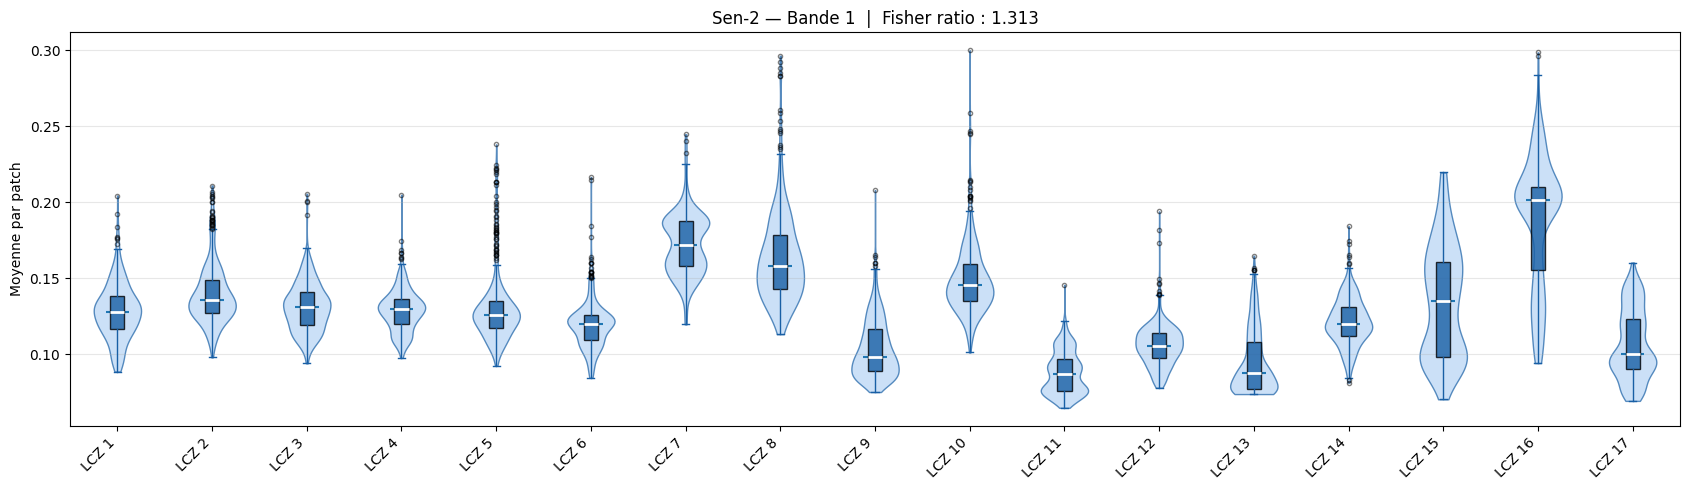

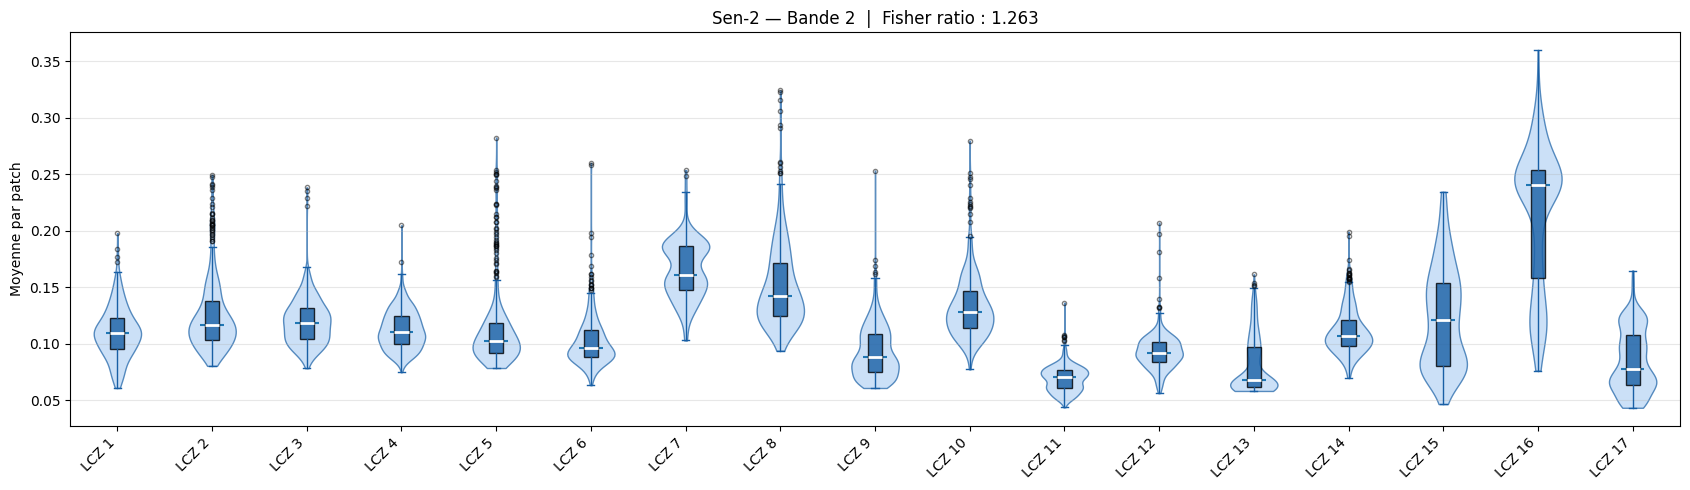

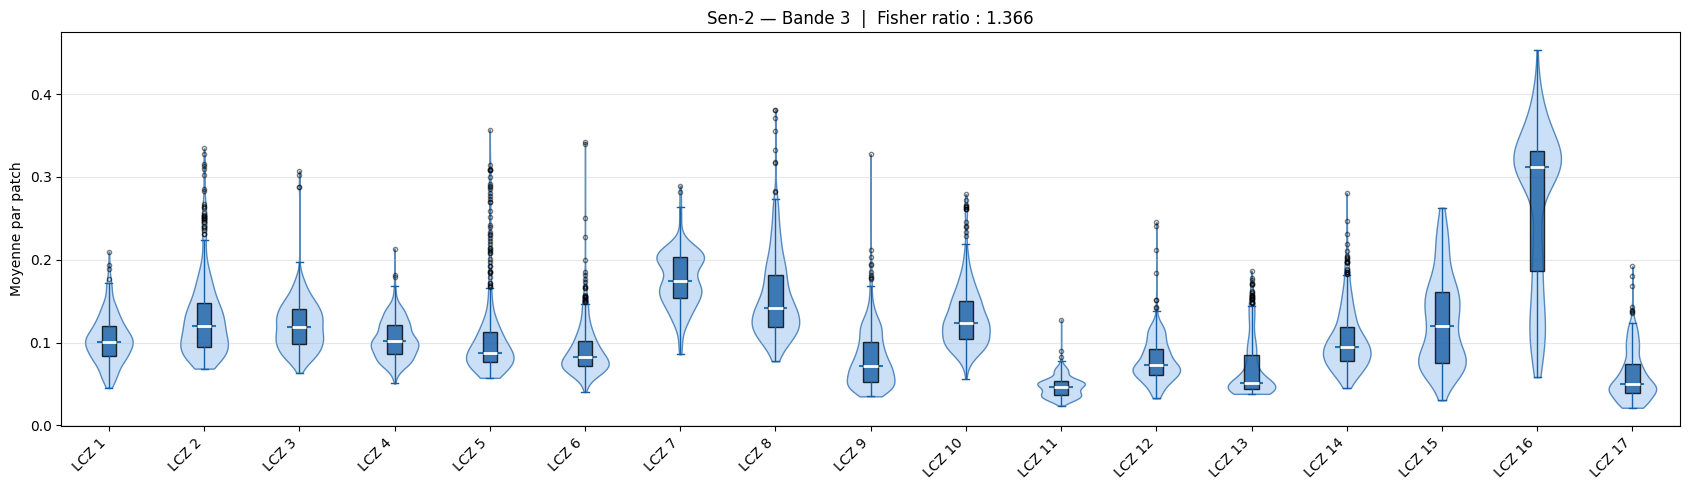

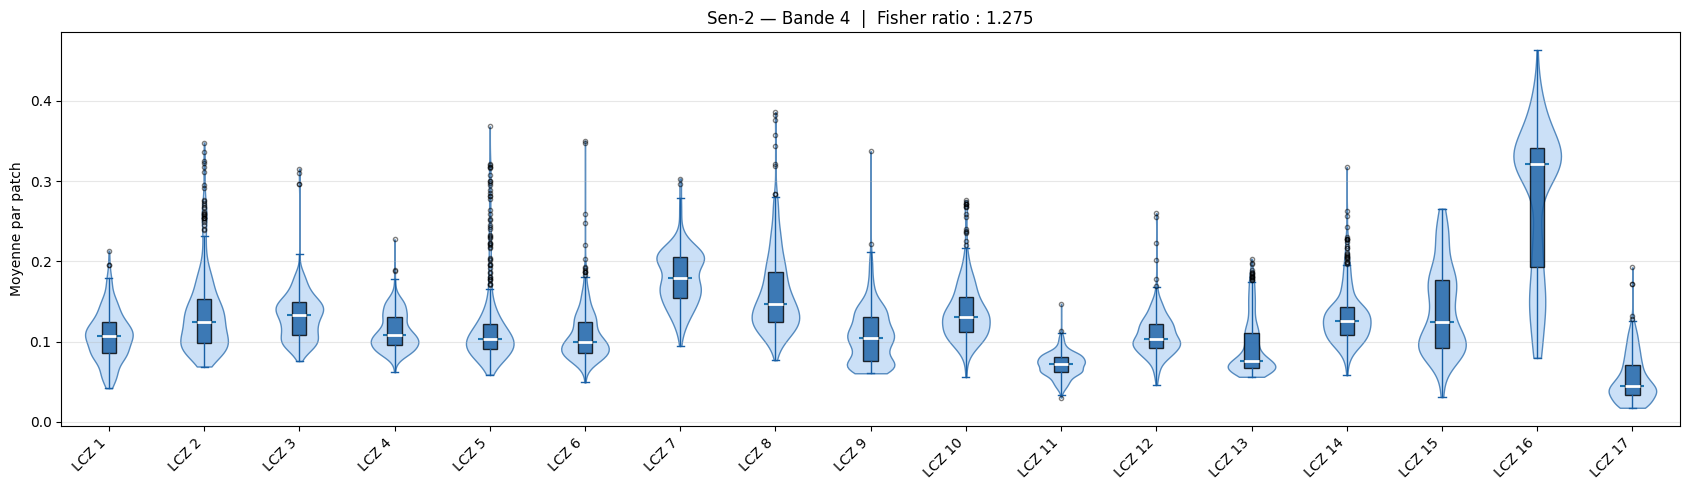

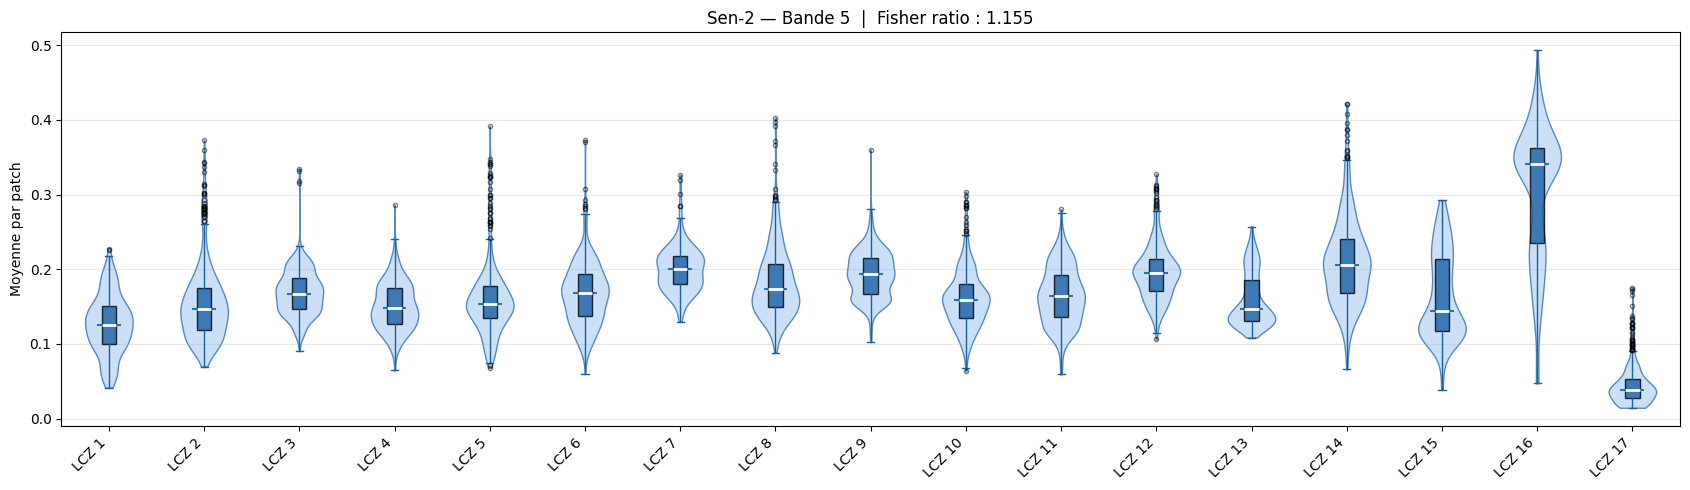

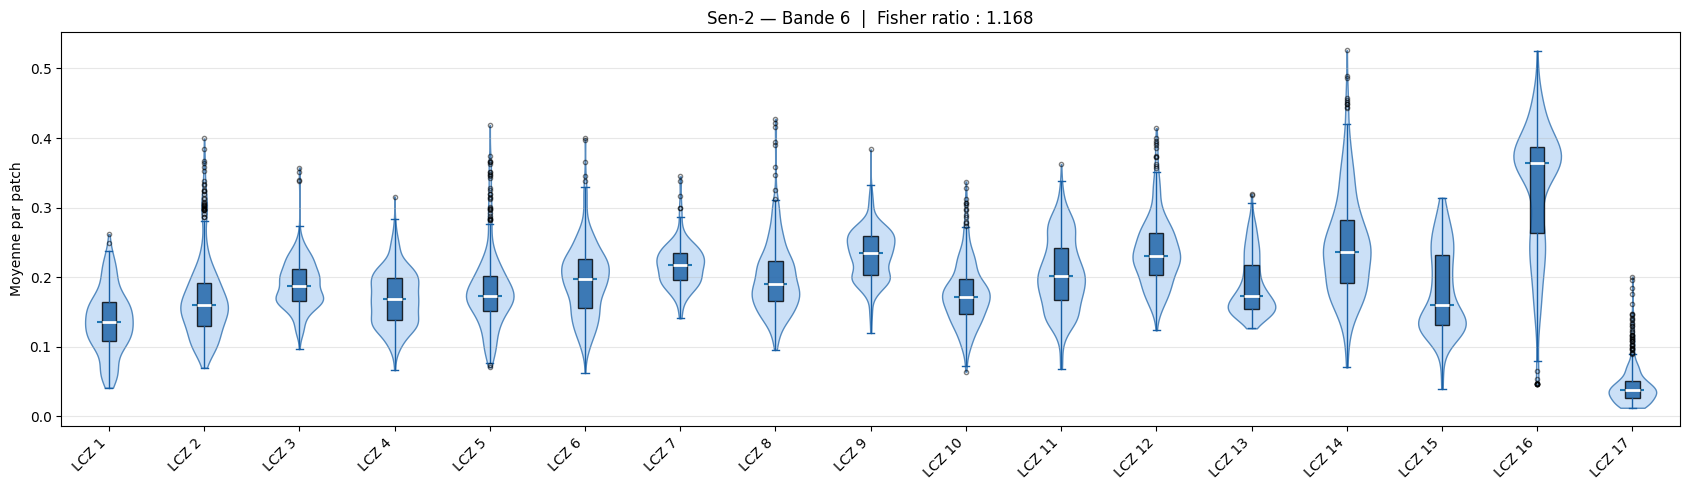

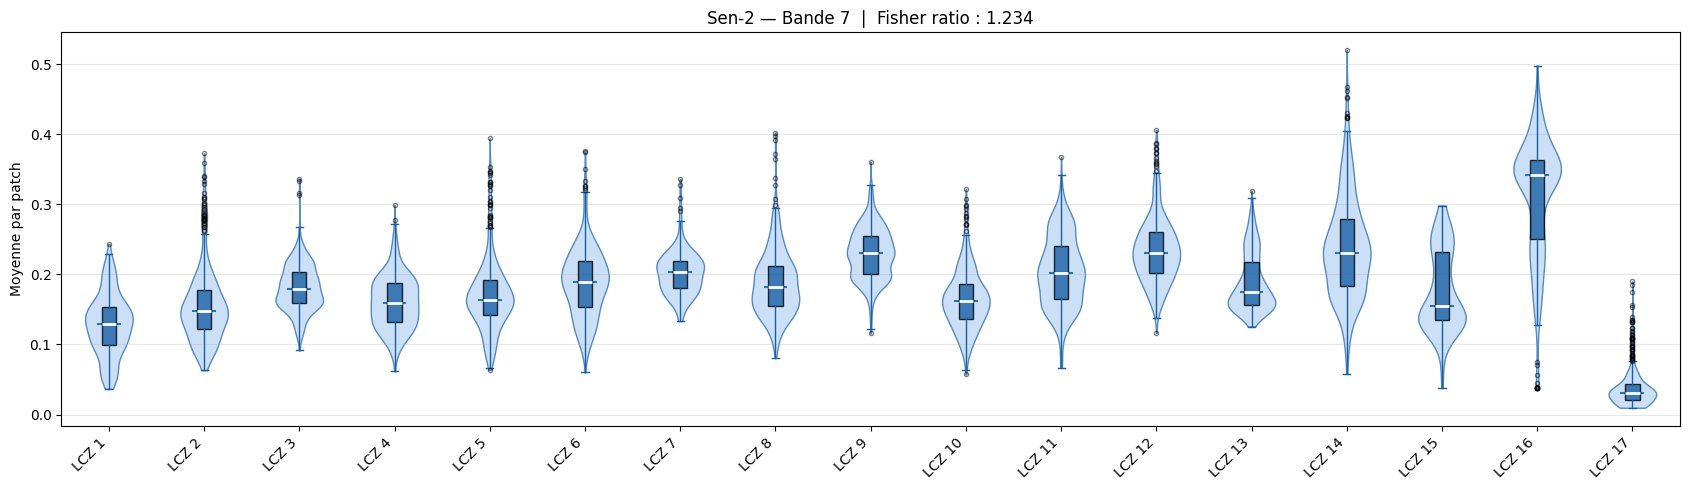

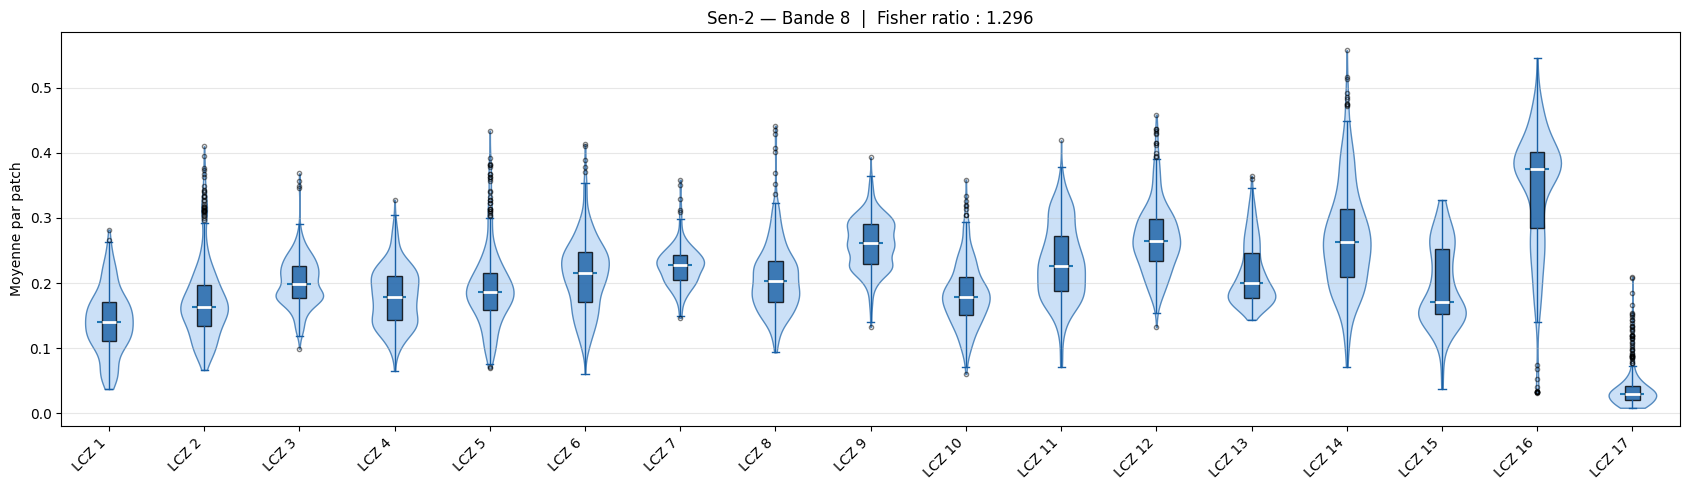

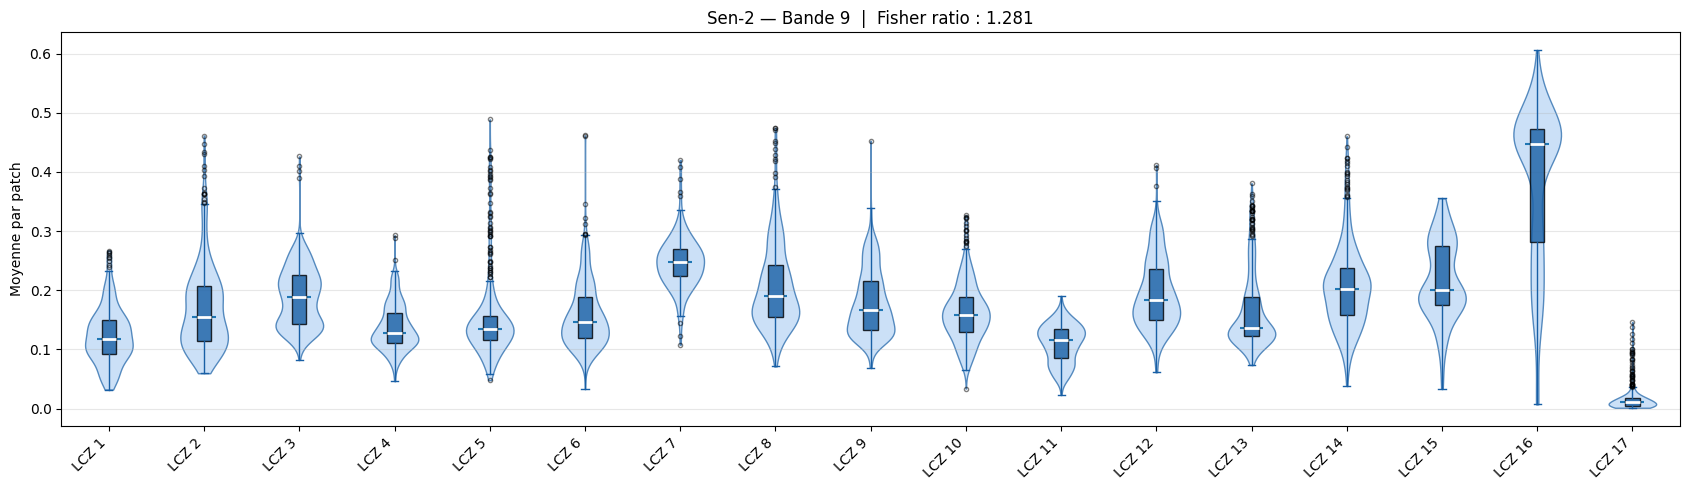

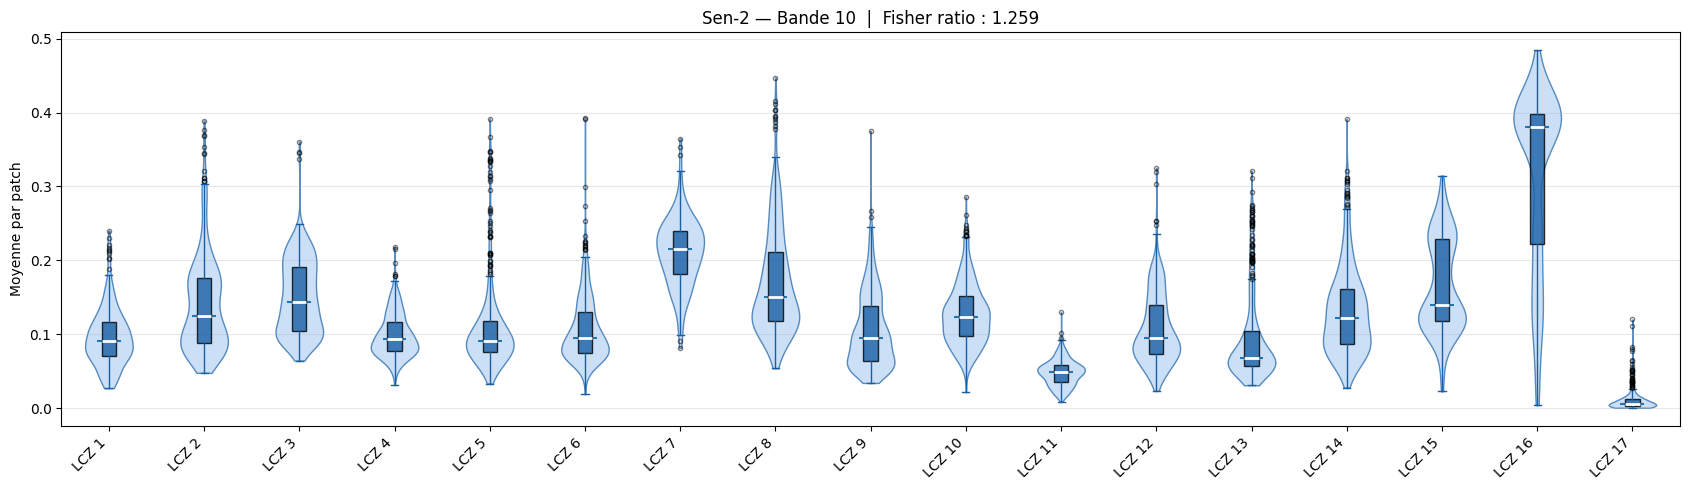

In [10]:
# Décodage one-hot → entiers
labels_int = np.argmax(label_sample, axis=1)

plot_violin_par_bande("Sen-2", labels_int, n_bandes=10)

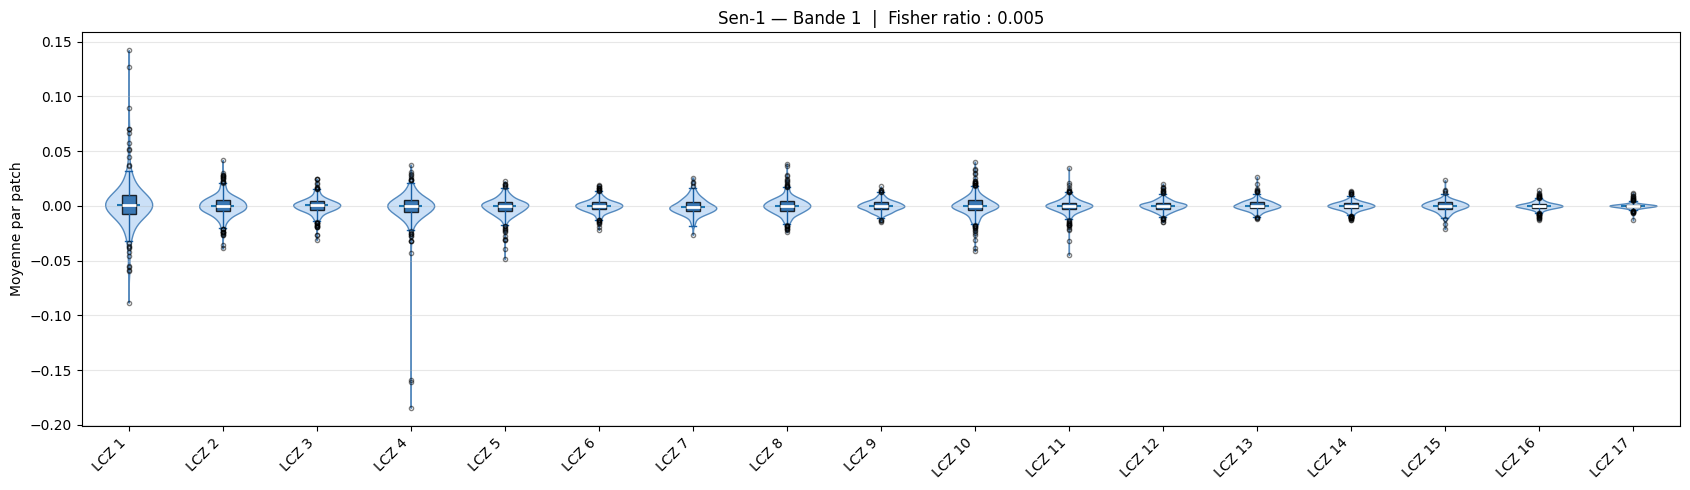

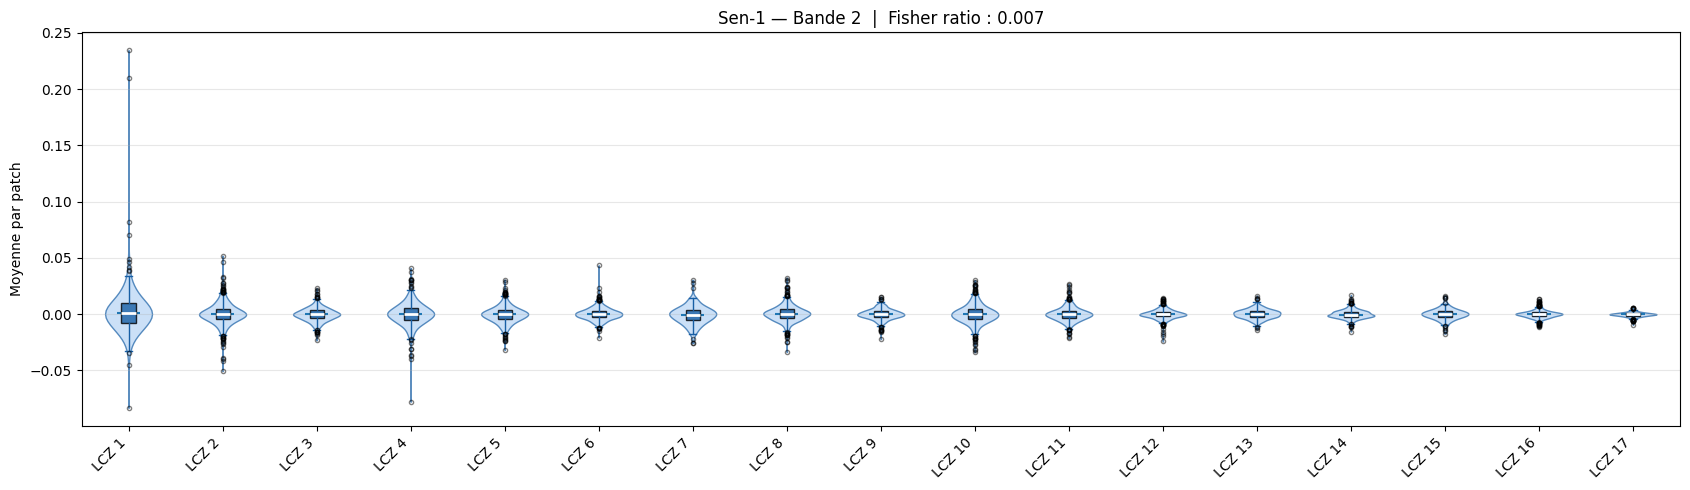

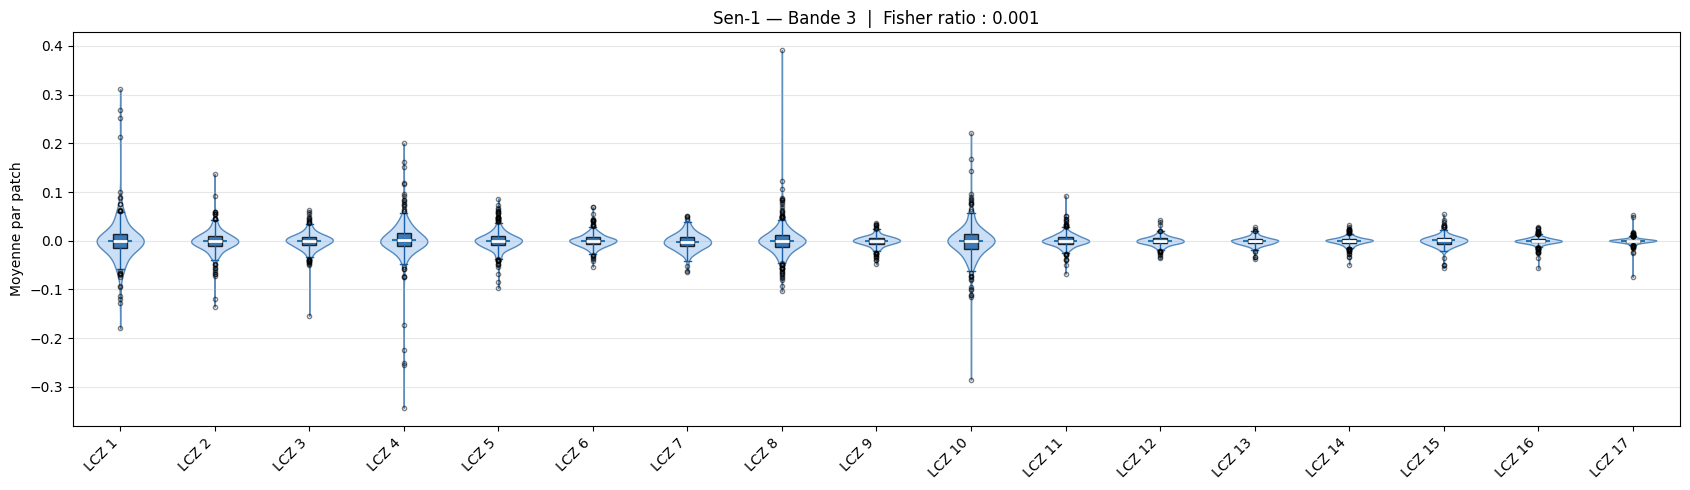

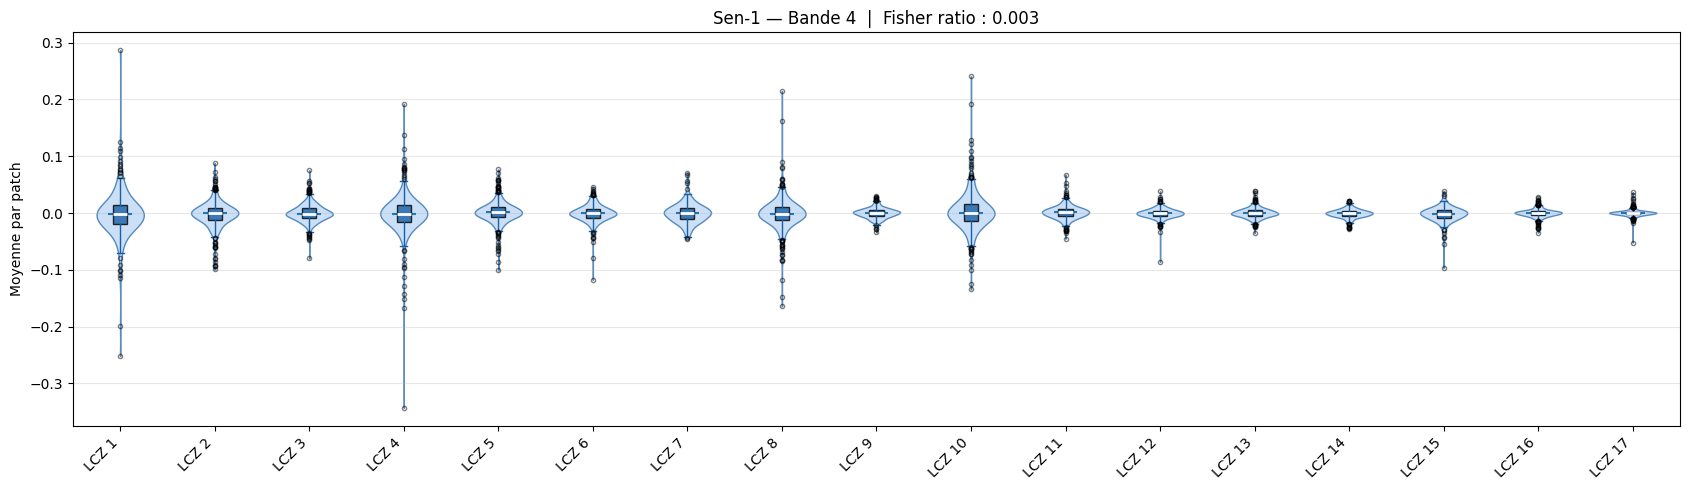

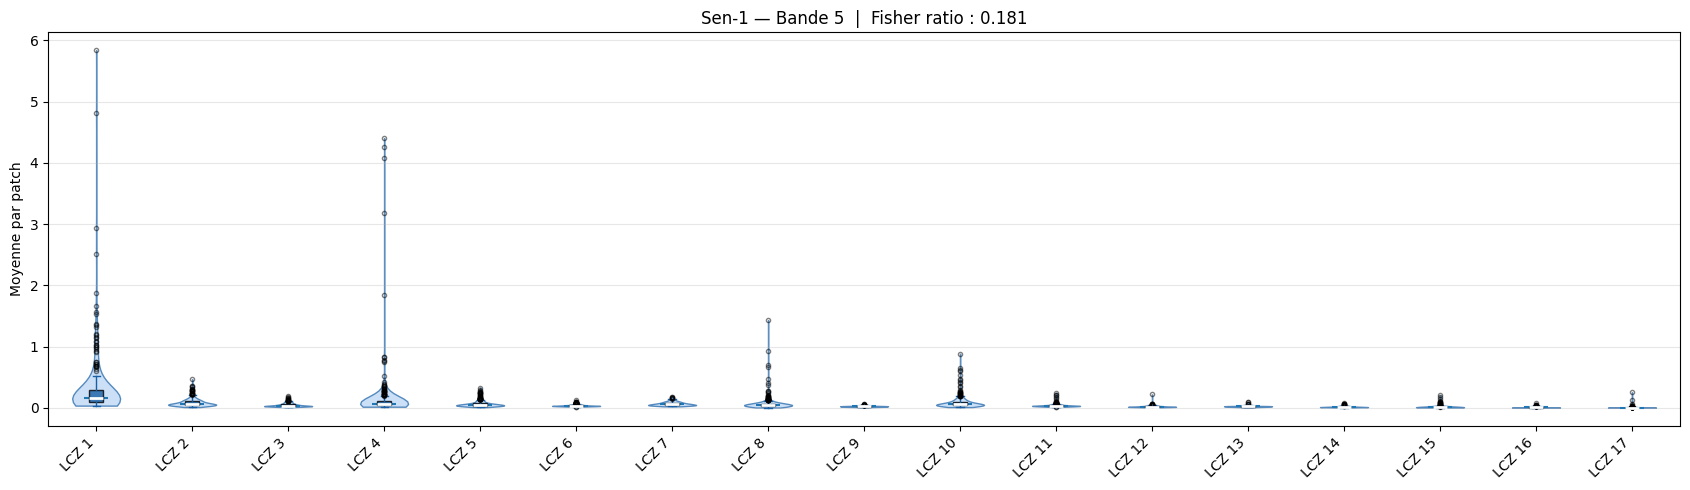

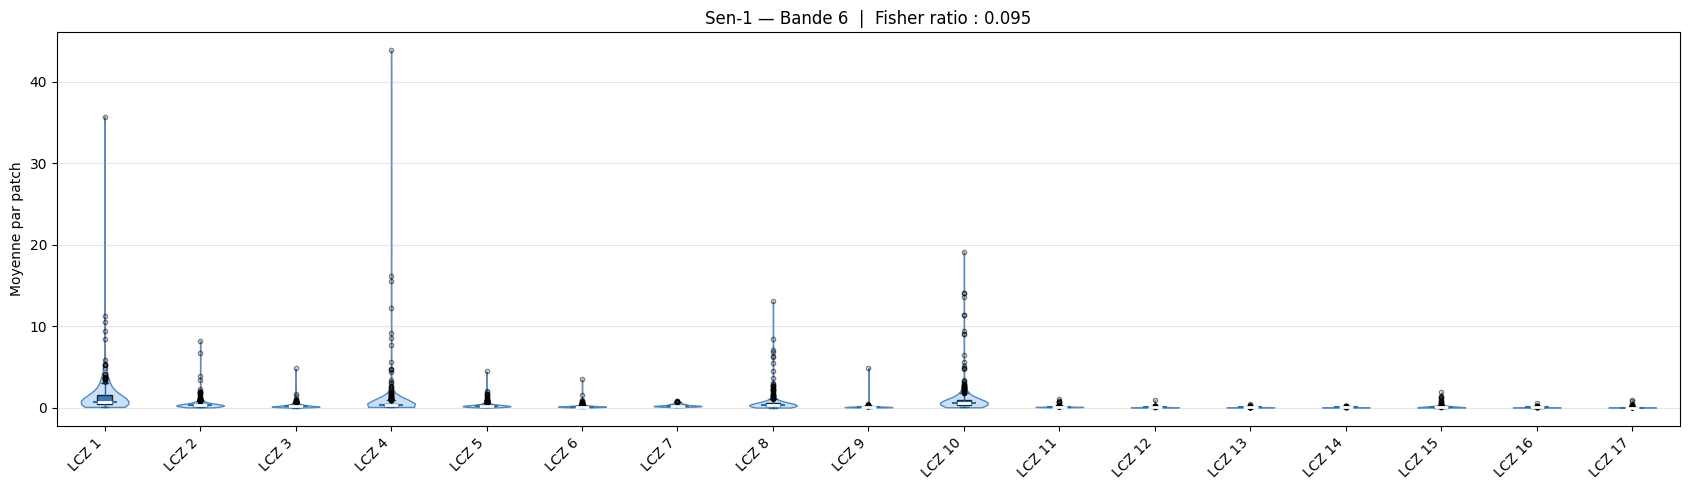

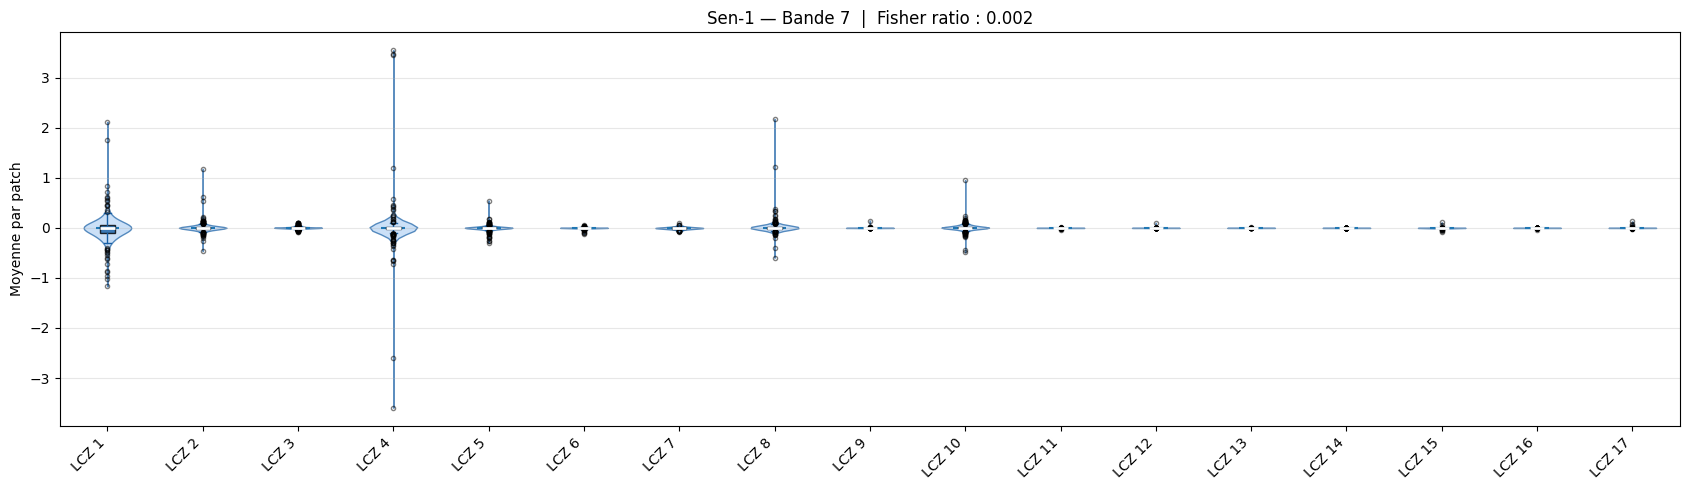

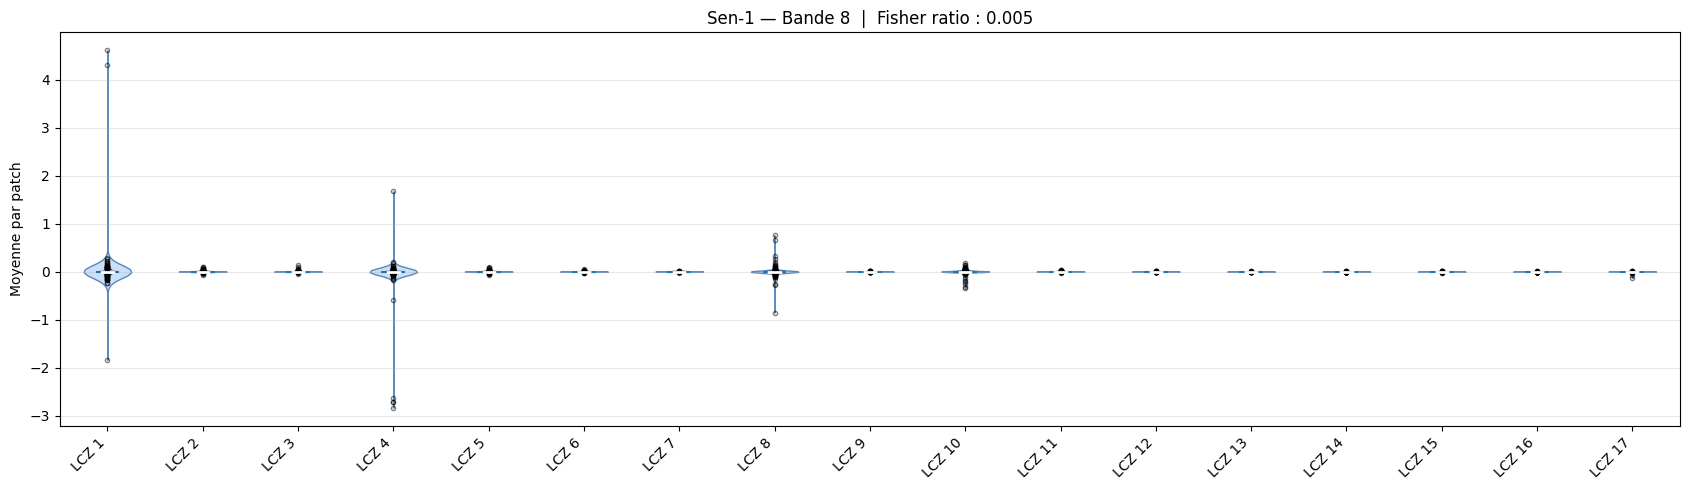

In [ ]:
# Essayer d'enlever les gros outliers pour voir tout est bien aussi aplati 
plot_violin_par_bande("Sen-1", labels_int, n_bandes=8)

Compte de tous les labels qu'il y a dans le validation set :
  1. Compact high-rise      :    256 ( 1.06%)
  2. Compact mid-rise       :   1254 ( 5.20%)
  3. Compact low-rise       :   2353 ( 9.76%)
  4. Open high-rise         :    849 ( 3.52%)
  5. Open mid-rise          :    757 ( 3.14%)
  6. Open low-rise          :   1906 ( 7.90%)
  7. Lightweight low-rise   :    474 ( 1.97%)
  8. Large low-rise         :   3395 (14.08%)
  9. Sparsely built         :   1914 ( 7.94%)
  10. Heavy industry        :    860 ( 3.57%)
  11. Dense trees            :   2287 ( 9.48%)
  12. Scattered trees        :    382 ( 1.58%)
  13. Bush, scrub            :   1202 ( 4.98%)
  14. Low plants             :   2747 (11.39%)
  15. Bare rock/paved        :    202 ( 0.84%)
  16. Bare soil/sand         :    672 ( 2.79%)
  17. Water                  :   2609 (10.82%)

In [8]:

def get_lcz_distribution_fast(h5_path: str, h5_name: str, class_names: list):
    """
    Calcule la répartition des classes LCZ en lisant uniquement les labels dans le HDF5.
    """
    print("Chargement rapide des labels...")
    with h5py.File(h5_path, 'r') as f:
        # Dans So2Sat, la clé est généralement 'label' (vecteurs one-hot de taille N x 17)
        # Si c'est déjà des entiers, ajustez selon la structure de votre h5
        raw_labels = f['label'][:] 
    
    # Comme les labels sont sous forme One-Hot, on extrait l'index de la classe
    targets = np.argmax(raw_labels, axis=1)

    # Compte rapide avec np.bincount ou np.unique
    unique_classes, counts = np.unique(targets, return_counts=True)
    total_samples = len(targets)
    target_dist = dict(zip(unique_classes, counts))

    print(f"\n Etude pour le set de {h5_name} : ")
    print(f"\nTotal d'échantillons : {total_samples}")
    print("Compte de tous les labels :")
    for c in range(len(class_names)):
        count = target_dist.get(c, 0)
        pct = 100 * count / total_samples
        print(f"  {class_names[c]:25s} : {count:6d} ({pct:5.2f}%)")

    return targets



In [10]:
# Noms officiels des 17 classes LCZ (Local Climate Zones) de So2Sat
LCZ_CLASSES = [
    "1. Compact high-rise", "2. Compact mid-rise", "3. Compact low-rise",
    "4. Open high-rise", "5. Open mid-rise", "6. Open low-rise",
    "7. Lightweight low-rise", "8. Large low-rise", "9. Sparsely built",
    "10. Heavy industry", "A. Dense trees", "B. Scattered trees",
    "C. Bush, scrub", "D. Low plants", "E. Bare rock/paved",
    "F. Bare soil/sand", "G. Water"
]

h5_train_path = "D:/LCZ42/training.h5"

# Exécution instantanée
y_true = get_lcz_distribution_fast(h5_train_path, "training", LCZ_CLASSES)

Chargement rapide des labels...

 Etude pour le set de training : 

Total d'échantillons : 352366
Compte de tous les labels :
  1. Compact high-rise      :   5068 ( 1.44%)
  2. Compact mid-rise       :  24431 ( 6.93%)
  3. Compact low-rise       :  31693 ( 8.99%)
  4. Open high-rise         :   8651 ( 2.46%)
  5. Open mid-rise          :  16493 ( 4.68%)
  6. Open low-rise          :  35290 (10.02%)
  7. Lightweight low-rise   :   3269 ( 0.93%)
  8. Large low-rise         :  39326 (11.16%)
  9. Sparsely built         :  13584 ( 3.86%)
  10. Heavy industry        :  11954 ( 3.39%)
  A. Dense trees            :  42902 (12.18%)
  B. Scattered trees        :   9514 ( 2.70%)
  C. Bush, scrub            :   9165 ( 2.60%)
  D. Low plants             :  41377 (11.74%)
  E. Bare rock/paved        :   2392 ( 0.68%)
  F. Bare soil/sand         :   7898 ( 2.24%)
  G. Water                  :  49359 (14.01%)


In [9]:
h5_val_path = "D:/LCZ42/validation.h5"

# Exécution instantanée
y_true = get_lcz_distribution_fast(h5_val_path, "validation", LCZ_CLASSES)

Chargement rapide des labels...

 Etude pour le set de validation : 

Total d'échantillons : 24119
Compte de tous les labels :
  1. Compact high-rise      :    256 ( 1.06%)
  2. Compact mid-rise       :   1254 ( 5.20%)
  3. Compact low-rise       :   2353 ( 9.76%)
  4. Open high-rise         :    849 ( 3.52%)
  5. Open mid-rise          :    757 ( 3.14%)
  6. Open low-rise          :   1906 ( 7.90%)
  7. Lightweight low-rise   :    474 ( 1.97%)
  8. Large low-rise         :   3395 (14.08%)
  9. Sparsely built         :   1914 ( 7.94%)
  10. Heavy industry        :    860 ( 3.57%)
  A. Dense trees            :   2287 ( 9.48%)
  B. Scattered trees        :    382 ( 1.58%)
  C. Bush, scrub            :   1202 ( 4.98%)
  D. Low plants             :   2747 (11.39%)
  E. Bare rock/paved        :    202 ( 0.84%)
  F. Bare soil/sand         :    672 ( 2.79%)
  G. Water                  :   2609 (10.82%)


Question de si il faut supprimer ou non l'apparition de la classe E qui crée simplement que du bruit pour notre modèle étant donné le peu de fois où il est présent...

In [10]:
h5_test_path = "D:/LCZ42/testing.h5"

# Exécution instantanée
y_true = get_lcz_distribution_fast(h5_test_path, "testing", LCZ_CLASSES)

Chargement rapide des labels...

 Etude pour le set de testing : 

Total d'échantillons : 24188
Compte de tous les labels :
  1. Compact high-rise      :    266 ( 1.10%)
  2. Compact mid-rise       :   1262 ( 5.22%)
  3. Compact low-rise       :   2465 (10.19%)
  4. Open high-rise         :    857 ( 3.54%)
  5. Open mid-rise          :    763 ( 3.15%)
  6. Open low-rise          :   1936 ( 8.00%)
  7. Lightweight low-rise   :    503 ( 2.08%)
  8. Large low-rise         :   3496 (14.45%)
  9. Sparsely built         :   2013 ( 8.32%)
  10. Heavy industry        :    908 ( 3.75%)
  A. Dense trees            :   2368 ( 9.79%)
  B. Scattered trees        :    433 ( 1.79%)
  C. Bush, scrub            :   1166 ( 4.82%)
  D. Low plants             :   2435 (10.07%)
  E. Bare rock/paved        :    205 ( 0.85%)
  F. Bare soil/sand         :    572 ( 2.36%)
  G. Water                  :   2540 (10.50%)


In [1]:
H5_DIR_CONTINENTS = "D:/LCZ42/per_continent/"

TEST_CONTINENT_TO_H5 = {
    "europe": H5_DIR_CONTINENTS + "testing_europe.h5",
    "afrique": H5_DIR_CONTINENTS + "testing_afrique.h5",
    "asie_ouest": H5_DIR_CONTINENTS + "testing_asie_ouest.h5",
    "asie_est": H5_DIR_CONTINENTS + "testing_asie_est.h5",
    "ameriquenord": H5_DIR_CONTINENTS + "testing_ameriquenord.h5",
    "ameriquesud": H5_DIR_CONTINENTS + "testing_ameriquesud.h5",
    "oceanie": H5_DIR_CONTINENTS + "testing_oceanie.h5",
}

VAL_CONTINENT_TO_H5 = {
    "europe": H5_DIR_CONTINENTS + "validation_europe.h5",
    "afrique": H5_DIR_CONTINENTS + "validation_afrique.h5",
    "asie_ouest": H5_DIR_CONTINENTS + "validation_asie_ouest.h5",
    "asie_est": H5_DIR_CONTINENTS + "validation_asie_est.h5",
    "ameriquenord": H5_DIR_CONTINENTS + "validation_ameriquenord.h5",
    "ameriquesud": H5_DIR_CONTINENTS + "validation_ameriquesud.h5",
    "oceanie": H5_DIR_CONTINENTS + "validation_oceanie.h5",
}

TRAIN_CONTINENT_TO_H5 = {
    "europe": H5_DIR_CONTINENTS + "training_europe.h5",
    "afrique": H5_DIR_CONTINENTS + "training_afrique.h5",
    "asie_ouest": H5_DIR_CONTINENTS + "training_asie_ouest.h5",
    "asie_est": H5_DIR_CONTINENTS + "training_asie_est.h5",
    "ameriquenord": H5_DIR_CONTINENTS + "training_ameriquenord.h5",
    "ameriquesud": H5_DIR_CONTINENTS + "training_ameriquesud.h5",
    "oceanie": H5_DIR_CONTINENTS + "training_oceanie.h5",
}

In [2]:
def get_repartition_continent_set(h5_name):
    print(f"Etude de la répartition des données par continent pour le jeu de données de {h5_name} :")
    if h5_name == "training":
        with h5py.File("D:/LCZ42/training.h5", 'r') as f:
            raw_labels_global = f['label'][:]
        
        continent_to_h5 = TRAIN_CONTINENT_TO_H5
    
    elif h5_name == "validation":
        with h5py.File("D:/LCZ42/validation.h5", 'r') as f:
            raw_labels_global = f['label'][:]
        
        continent_to_h5 = VAL_CONTINENT_TO_H5

    elif h5_name == "testing":
        with h5py.File("D:/LCZ42/testing.h5", 'r') as f:
            raw_labels_global = f['label'][:]
        
        continent_to_h5 = TEST_CONTINENT_TO_H5

    else:
        assert(ValueError("h5_name a un nom invalide qui ne correspond à aucun des choix suivants : 'training', 'validation', 'testing'"))
    
    targets_global = np.argmax(raw_labels_global, axis=1)
    total_samples = len(targets_global)

    for k, v in continent_to_h5.items():
        with h5py.File(v, "r") as f:
            raw_labels_continent = f["label"][:]
        total_sample_per_continent = len(raw_labels_continent)
        pourcentage_per_cont = 100*total_sample_per_continent/total_samples
        print(f"{k} : {total_sample_per_continent} ({pourcentage_per_cont:.2f}%)")
    


In [4]:
get_repartition_continent_set("testing")

Etude de la répartition des données par continent pour le jeu de données de testing :
europe : 4840 (20.01%)
afrique : 2417 (9.99%)
asie_ouest : 4837 (20.00%)
asie_est : 4840 (20.01%)
ameriquenord : 2417 (9.99%)
ameriquesud : 2418 (10.00%)
oceanie : 2419 (10.00%)


In [5]:
get_repartition_continent_set("training")

Etude de la répartition des données par continent pour le jeu de données de training :
europe : 97282 (27.61%)
afrique : 28697 (8.14%)
asie_ouest : 29312 (8.32%)
asie_est : 59033 (16.75%)
ameriquenord : 68330 (19.39%)
ameriquesud : 33307 (9.45%)
oceanie : 36405 (10.33%)


In [6]:
get_repartition_continent_set("validation")

Etude de la répartition des données par continent pour le jeu de données de validation :
europe : 4823 (20.00%)
afrique : 2411 (10.00%)
asie_ouest : 4824 (20.00%)
asie_est : 4824 (20.00%)
ameriquenord : 2413 (10.00%)
ameriquesud : 2413 (10.00%)
oceanie : 2411 (10.00%)


In [11]:
for k, v in TEST_CONTINENT_TO_H5.items():
    h5_name = "testing_"+ k
    y_true = get_lcz_distribution_fast(v, h5_name, LCZ_CLASSES)
    print("\n=============================\n")
    

Chargement rapide des labels...

 Etude pour le set de testing_europe : 

Total d'échantillons : 4840
Compte de tous les labels :
  1. Compact high-rise      :      0 ( 0.00%)
  2. Compact mid-rise       :    335 ( 6.92%)
  3. Compact low-rise       :      6 ( 0.12%)
  4. Open high-rise         :    445 ( 9.19%)
  5. Open mid-rise          :    396 ( 8.18%)
  6. Open low-rise          :    438 ( 9.05%)
  7. Lightweight low-rise   :      7 ( 0.14%)
  8. Large low-rise         :    533 (11.01%)
  9. Sparsely built         :    268 ( 5.54%)
  10. Heavy industry        :    147 ( 3.04%)
  A. Dense trees            :    791 (16.34%)
  B. Scattered trees        :     57 ( 1.18%)
  C. Bush, scrub            :     19 ( 0.39%)
  D. Low plants             :    822 (16.98%)
  E. Bare rock/paved        :     11 ( 0.23%)
  F. Bare soil/sand         :      8 ( 0.17%)
  G. Water                  :    557 (11.51%)


Chargement rapide des labels...

 Etude pour le set de testing_afrique : 

Total d'éch

In [12]:
for k, v in VAL_CONTINENT_TO_H5.items():
    h5_name = "validation_"+ k
    y_true = get_lcz_distribution_fast(v, h5_name, LCZ_CLASSES)
    print("\n=============================\n")

Chargement rapide des labels...

 Etude pour le set de validation_europe : 

Total d'échantillons : 4823
Compte de tous les labels :
  1. Compact high-rise      :      0 ( 0.00%)
  2. Compact mid-rise       :    331 ( 6.86%)
  3. Compact low-rise       :      9 ( 0.19%)
  4. Open high-rise         :    440 ( 9.12%)
  5. Open mid-rise          :    392 ( 8.13%)
  6. Open low-rise          :    444 ( 9.21%)
  7. Lightweight low-rise   :      6 ( 0.12%)
  8. Large low-rise         :    528 (10.95%)
  9. Sparsely built         :    273 ( 5.66%)
  10. Heavy industry        :    145 ( 3.01%)
  A. Dense trees            :    792 (16.42%)
  B. Scattered trees        :     57 ( 1.18%)
  C. Bush, scrub            :     18 ( 0.37%)
  D. Low plants             :    814 (16.88%)
  E. Bare rock/paved        :     10 ( 0.21%)
  F. Bare soil/sand         :      8 ( 0.17%)
  G. Water                  :    556 (11.53%)


Chargement rapide des labels...

 Etude pour le set de validation_afrique : 

Total

In [13]:
for k, v in TRAIN_CONTINENT_TO_H5.items():
    h5_name = "training_"+ k
    y_true = get_lcz_distribution_fast(v, h5_name, LCZ_CLASSES)
    print("\n=============================\n")

Chargement rapide des labels...

 Etude pour le set de training_europe : 

Total d'échantillons : 97282
Compte de tous les labels :
  1. Compact high-rise      :    387 ( 0.40%)
  2. Compact mid-rise       :   9328 ( 9.59%)
  3. Compact low-rise       :    434 ( 0.45%)
  4. Open high-rise         :   1258 ( 1.29%)
  5. Open mid-rise          :  10257 (10.54%)
  6. Open low-rise          :  17253 (17.74%)
  7. Lightweight low-rise   :      0 ( 0.00%)
  8. Large low-rise         :   8663 ( 8.91%)
  9. Sparsely built         :   1135 ( 1.17%)
  10. Heavy industry        :   2930 ( 3.01%)
  A. Dense trees            :  11824 (12.15%)
  B. Scattered trees        :   3779 ( 3.88%)
  C. Bush, scrub            :    344 ( 0.35%)
  D. Low plants             :  18196 (18.70%)
  E. Bare rock/paved        :     77 ( 0.08%)
  F. Bare soil/sand         :    237 ( 0.24%)
  G. Water                  :  11180 (11.49%)


Chargement rapide des labels...

 Etude pour le set de training_afrique : 

Total d'